# Fractional difference: small weights can leave a large tail

## tl;dr
This audit separates truncation error, floating-point agreement and initialization. An individual coefficient threshold is not a bound on accumulated error; a finite-horizon tail-mass budget is. Full direct and properly padded FFT are numerical baselines. All empirical values below come from executed artifacts, not claims about economic memory.

## Context & Methods
### Key Assumptions
Discrete y(t)=Σ w(k)x(t−k), w(k)=(−1)^k binom(d,k), step one. 0<d<1, zero extension for negative t, known finite horizon N and bounded input. This is not automatically a Caputo derivative, stationary infinite-past filter or a test for long memory.

### 1. Load the configuration and execution checks

In [1]:
import csv, json
from pathlib import Path
import numpy as np
from IPython.display import display, Image
from src.fractional import weights, tail_masses, coefficient_memory, budget_memory, apply_filter
from src.reference import prefix_gamma, oracle_filter
config=json.loads(Path('config.json').read_text())
result=json.loads(Path('benchmarks/results.json').read_text())
print(config['question'])
print(json.dumps(result['checks'],indent=2))
assert all(result['passed'].values())

Does a small last fractional-difference coefficient control accumulated truncation error, and can a finite-horizon tail budget guarantee the requested bound?
{
  "max_fft_scaled_error": 1.0685896612017132e-15,
  "max_tail_bound_violation": 1.0685896612017132e-15,
  "max_budget_error": 0.009999418935581428,
  "max_oracle_scaled_error": 6.106226635438361e-16,
  "min_cutoff_error_over_epsilon": 117.60242701828483,
  "max_constant_bound_gap": 4.996003610813204e-16,
  "min_circular_wraparound_error": 0.4
}


### 2. Verify the weights and Gamma prefix
w₀=1; wₖ=wₖ₋₁(k−1−d)/k. For 0<d<1 the remaining weights are negative. The prefix rₘ=Γ(m+1−d)/[Γ(1−d)Γ(m+1)] is positive and tends to zero slowly.

In [2]:
w=weights(.4,64)
print('first weights:',w[:6])
for m in (0,1,7,63):
    print('m=',m,'sum=',float(w[:m+1].sum()),'Gamma oracle=',prefix_gamma(.4,m))
assert np.all(w[1:]<0)

first weights: [ 1.       -0.4      -0.12     -0.064    -0.0416   -0.029952]
m= 0 sum= 1.0 Gamma oracle= 1.0
m= 1 sum= 0.6 Gamma oracle= 0.6
m= 7 sum= 0.30311424 Gamma oracle= 0.30311424
m= 63 sum= 0.12778686966801478 Gamma oracle= 0.12778686966801475


## Data
36 scenarios: three d, three lengths and four bounded input families. The 12 unique input series are saved in benchmarks/inputs.npz; d changes the filter, not the input. 216 method results and 648 timing records. Three timing repetitions are not independent statistical replicates. Config and CSVs record seeds, memory indexing and timing scope.

### 3. Recompute the coefficient-cutoff counterexample

In [3]:
n=8192
d=.4
x=np.ones(n)
w=weights(d,n)
m=coefficient_memory(w,.001)
full=apply_filter(x,w)
cut=apply_filter(x,w,m)
error=float(np.max(np.abs(cut-full)))
print({'retained_max_lag':m,'first_discarded_weight':float(w[m+1]),'max_error':error,'tail_bound':float(tail_masses(w)[m]),'error_over_epsilon':error/.001})
assert abs(w[m+1])<=.001 and error>20*.001

{'retained_max_lag': 54, 'first_discarded_weight': -0.000988153790546045, 'max_error': 0.11760242701828483, 'tail_bound': 0.11760242701828463, 'error_over_epsilon': 117.60242701828483}


### 4. Verify the finite-horizon error proposition
For |x|≤M, truncating after m gives |error(t)|≤MΣ(k=m+1..t)|wₖ|≤M T(m,N). Because all omitted weights share a sign, T(m,N)=rₘ−r(N−1). A constant unit input attains the bound at the last time. The selector chooses the smallest m with T≤η. The bound is relative to input scale, not to an output that may be nearly zero.

In [4]:
for d in config['grid']['d']:
    w=weights(d,8192)
    m=budget_memory(w,.01)
    tail=tail_masses(w)
    y=apply_filter(np.ones(8192),w,m)
    yfull=apply_filter(np.ones(8192),w)
    err=float(np.max(np.abs(y-yfull)))
    print({'d':d,'memory':m,'retained_fraction':(m+1)/8192,'error':err,'bound':float(tail[m])})
    assert err<=.0100000001
    assert m==0 or tail[m-1]>.01

{'d': 0.1, 'memory': 6318, 'retained_fraction': 0.7713623046875, 'error': 0.009995854491178624, 'bound': 0.009995854491178536}
{'d': 0.4, 'memory': 2750, 'retained_fraction': 0.3358154296875, 'error': 0.009999418935581428, 'bound': 0.009999418935581284}
{'d': 0.8, 'memory': 47, 'retained_fraction': 0.005859375, 'error': 0.009831602619295388, 'bound': 0.009831602619295273}


## Results
### 5. Inspect accuracy and cost together
Timing includes validation/filtering, excludes weight/selector setup, and uses fixed order. Setup is recorded separately. Peak tracked allocation is not process RSS. Do not infer universal speed superiority from these local measurements.

In [5]:
with open('benchmarks/summary.csv') as f:
    summary=list(csv.DictReader(f))
for row in summary:
    if row['family']=='ar1' and row['d']=='0.4' and row['method'] in ('full_direct','full_fft','tail_budget'):
        print({k:row[k] for k in ('n','method','memory','scaled_error','median_seconds','tracked_peak_bytes')})

{'n': '256', 'method': 'full_direct', 'memory': '255', 'scaled_error': '0.0', 'median_seconds': '2.4205999920923205e-05', 'tracked_peak_bytes': '6755'}
{'n': '256', 'method': 'full_fft', 'memory': '255', 'scaled_error': '2.7755575615628914e-16', 'median_seconds': '9.133800006111414e-05', 'tracked_peak_bytes': '18007'}
{'n': '256', 'method': 'tail_budget', 'memory': '186', 'scaled_error': '0.0019179335605261014', 'median_seconds': '2.9335000022001623e-05', 'tracked_peak_bytes': '6755'}
{'n': '2048', 'method': 'full_direct', 'memory': '2047', 'scaled_error': '0.0', 'median_seconds': '0.0005850720000353249', 'tracked_peak_bytes': '49763'}
{'n': '2048', 'method': 'full_fft', 'memory': '2047', 'scaled_error': '2.7755575615628914e-16', 'median_seconds': '0.00025911100010489463', 'tracked_peak_bytes': '132708'}
{'n': '2048', 'method': 'tail_budget', 'memory': '1034', 'scaled_error': '0.0006970536978916919', 'median_seconds': '0.0004031280000162951', 'tracked_peak_bytes': '49763'}
{'n': '8192'

### 6. Distinguish boundary assumptions from numerical error
A full zero-extended unit constant has output r(t), not zero. Circular FFT without padding wraps a future end-pulse into the start; this deliberately incorrect ablation is not a competitive baseline.

In [6]:
z=np.zeros(64)
z[-1]=1
w=weights(.4,64)
linear=apply_filter(z,w,method='fft')
circular=np.fft.irfft(np.fft.rfft(z)*np.fft.rfft(w),n=64)
print({'linear_at_start':float(linear[0]),'circular_at_start':float(circular[0]),'zero_extended_constant_at_last':prefix_gamma(.4,8191)})
assert abs(linear[0])<1e-12 and abs(circular[0])>.1

{'linear_at_start': 0.0, 'circular_at_start': -0.4, 'zero_extended_constant_at_last': 0.0182687191817959}


### 7. Inspect the three-part figure
Left: accumulated error on the unit constant. Middle: fraction of retained coefficients, not total-program memory savings. Right: full-history direct and linear FFT timings.

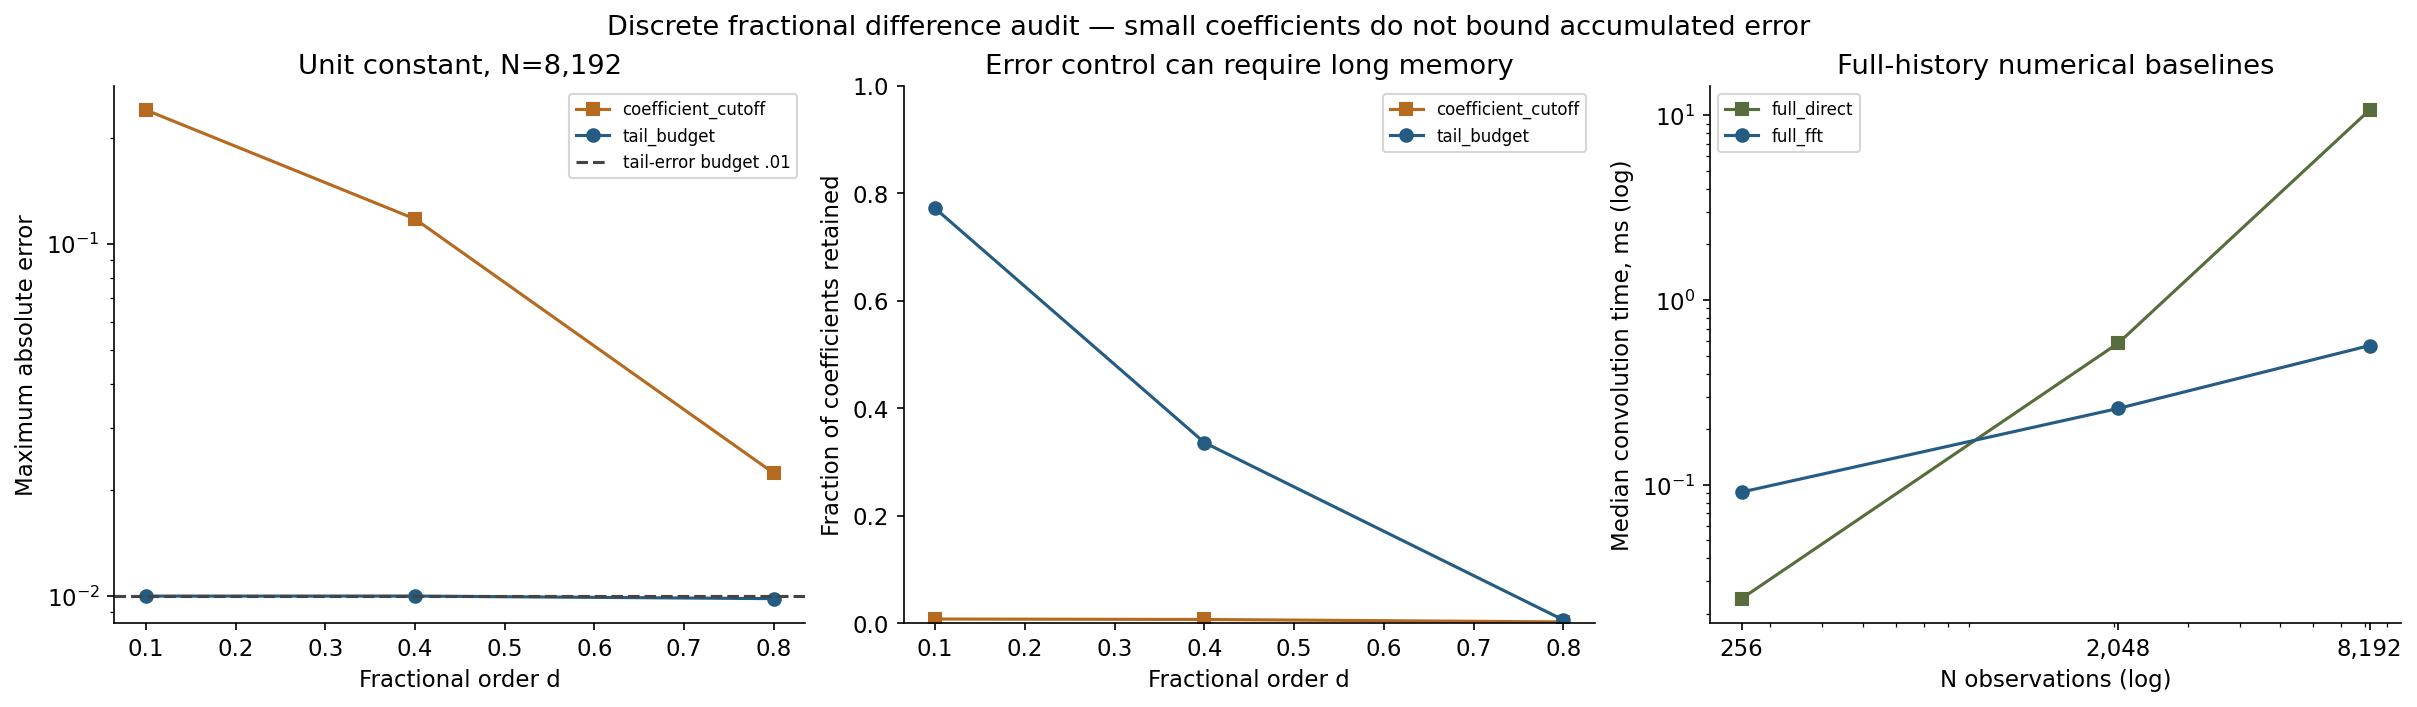

In [7]:
display(Image(filename='benchmarks/audit.png'))

### 8. Recompute a short-series high-precision reference
The reference uses mpmath binomial special functions and 80-digit summation, not the same float recurrence. It is deliberately limited to short inputs.

In [8]:
x=np.random.default_rng(191905).uniform(-1,1,64)
w=weights(.4,len(x))
ref=oracle_filter(x,.4)
print({'direct_vs_80_digits':float(np.max(np.abs(apply_filter(x,w)-ref))),'fft_vs_80_digits':float(np.max(np.abs(apply_filter(x,w,method='fft')-ref)))})
assert np.max(np.abs(apply_filter(x,w)-ref))<1e-11

{'direct_vs_80_digits': 2.220446049250313e-16, 'fft_vs_80_digits': 3.3306690738754696e-16}


## Takeaways
A coefficient threshold can leave a large accumulated tail. The finite-horizon budget controls truncation under bounded inputs; small d may require almost full history. FFT needs padding to preserve linear convolution. Initialization is part of the model.

Limits: scalar discrete operator, fixed known d/N, float64 verification rather than formal interval certification. No Hurst estimation, distinction between economic long memory and breaks, streaming implementation, continuous fractional SDE or financial validation. See informe.md, referencias.bib and fuentes.md for derivations, prior art and source-access limits.